# Prédire la fatigue d'un athlète (`fatigue_index`)

Même notebook que `notebook projet.ipynb`, avec une seule différence : les valeurs manquantes sont remplacées par la **médiane** au lieu de la moyenne.

- Données : le vrai jeu Kaggle (15 420 séances), football et basket.
- `fatigue_index` est retirée des variables explicatives, puisque c'est ce qu'on prédit.
- `injury_occurred` n'est pas utilisée : la blessure est une conséquence de la fatigue, pas une cause.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn import metrics

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [2]:
df = pd.read_csv("multimodal_sports_injury_dataset_kaggle.csv")
print(df["sport_type"].value_counts())

sport_type
Soccer        4837
Track         4147
Basketball    4059
Other         2377
Name: count, dtype: int64


In [3]:
# sports proches du football (consigne du prof) : football et basket
df_soccer = df[df["sport_type"].isin(["Soccer", "Basketball"])].copy()
count_soccer = len(df_soccer)
print(count_soccer)

8896


In [ ]:
from google.colab import files

uploaded = files.upload()

In [4]:
df.head()

,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,...,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,sport_type,gender,age,bmi
0,1,NaN,37.048668,76.481477,5.466370,77.899691,0.375825,10.000000,126.480118,2.654327,...,5.678475,79.106564,548.417962,45.028687,0,1,Basketball,Female,18,25.105748
1,1,40.000000,36.929536,72.363938,6.899090,74.845323,0.279165,310.293156,157.631630,3.431107,...,NaN,116.954654,538.043815,42.254717,2,2,Basketball,Female,18,25.105748
2,1,76.174609,36.334841,100.000000,9.574152,83.538316,0.334061,158.659094,81.766287,0.800000,...,6.643242,96.354742,647.784339,61.870056,0,3,Basketball,Female,18,25.105748
3,1,100.543724,37.244474,86.172473,7.614297,79.966618,0.218766,107.079298,113.023701,1.713869,...,6.194427,97.619130,336.553431,50.268845,0,4,Basketball,Female,18,25.105748
4,1,78.001235,36.510766,83.195889,5.631979,56.945979,0.484086,164.347133,112.814695,2.154233,...,5.835804,83.155527,496.076352,29.233575,2,5,Basketball,Female,18,25.105748


In [5]:
print(df.columns)

Index(['athlete_id', 'heart_rate', 'body_temperature', 'hydration_level',
       'sleep_quality', 'recovery_score', 'stress_level', 'muscle_activity',
       'joint_angles', 'gait_speed', 'cadence', 'step_count', 'jump_height',
       'ground_reaction_force', 'range_of_motion', 'ambient_temperature',
       'humidity', 'altitude', 'playing_surface', 'training_intensity',
       'training_duration', 'training_load', 'fatigue_index',
       'injury_occurred', 'session_id', 'sport_type', 'gender', 'age', 'bmi'],
      dtype='object')


In [6]:
df.isna()

,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,...,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,sport_type,gender,age,bmi
0,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15415,False,False,False,False,False,False,False,True,False,True,...,False,False,False,False,False,False,False,False,False,False
15416,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
15417,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
15418,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [7]:
df_soccer.isna().sum()

athlete_id                 0
heart_rate               207
body_temperature           0
hydration_level          237
sleep_quality            281
recovery_score             0
stress_level               0
muscle_activity          348
joint_angles               0
gait_speed               247
cadence                    0
step_count                 0
jump_height                0
ground_reaction_force      0
range_of_motion            0
ambient_temperature        0
humidity                   0
altitude                   0
playing_surface            0
training_intensity       390
training_duration          0
training_load              0
fatigue_index              0
injury_occurred            0
session_id                 0
sport_type                 0
gender                     0
age                        0
bmi                        0
dtype: int64

In [8]:
# pourcentage de donnees manquantes sur la totalite du fichier (toutes les cases, avant remplissage)
print(round(df.isna().sum().sum() / df.size * 100, 2), '%')

0.64 %


In [9]:
df.shape

(15420, 29)

In [10]:
df_soccer["heart_rate"] = df_soccer["heart_rate"].fillna(df_soccer["heart_rate"].median())

In [11]:
df_soccer["hydration_level"] = df_soccer["hydration_level"].fillna(df_soccer["hydration_level"].median())

In [12]:
df_soccer["training_intensity"] = df_soccer["training_intensity"].fillna(df_soccer["training_intensity"].median())

In [13]:
df_soccer["sleep_quality"] = df_soccer["sleep_quality"].fillna(df_soccer["sleep_quality"].median())

In [14]:
df_soccer["muscle_activity"] = df_soccer["muscle_activity"].fillna(df_soccer["muscle_activity"].median())

In [15]:
df_soccer["gait_speed"] = df_soccer["gait_speed"].fillna(df_soccer["gait_speed"].median())

In [16]:
df_soccer.isna().sum()

athlete_id               0
heart_rate               0
body_temperature         0
hydration_level          0
sleep_quality            0
recovery_score           0
stress_level             0
muscle_activity          0
joint_angles             0
gait_speed               0
cadence                  0
step_count               0
jump_height              0
ground_reaction_force    0
range_of_motion          0
ambient_temperature      0
humidity                 0
altitude                 0
playing_surface          0
training_intensity       0
training_duration        0
training_load            0
fatigue_index            0
injury_occurred          0
session_id               0
sport_type               0
gender                   0
age                      0
bmi                      0
dtype: int64

In [17]:
print(df_soccer.columns)

Index(['athlete_id', 'heart_rate', 'body_temperature', 'hydration_level',
       'sleep_quality', 'recovery_score', 'stress_level', 'muscle_activity',
       'joint_angles', 'gait_speed', 'cadence', 'step_count', 'jump_height',
       'ground_reaction_force', 'range_of_motion', 'ambient_temperature',
       'humidity', 'altitude', 'playing_surface', 'training_intensity',
       'training_duration', 'training_load', 'fatigue_index',
       'injury_occurred', 'session_id', 'sport_type', 'gender', 'age', 'bmi'],
      dtype='object')


In [18]:
df_soccer["fatigue_index"].describe()

count    8896.000000
mean       59.485050
std        25.142969
min        15.000000
25%        41.501922
50%        57.112199
75%        74.818826
max       270.193219
Name: fatigue_index, dtype: float64

In [19]:
df_soccer.describe()

,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,...,altitude,playing_surface,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,age,bmi
count,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,...,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000,8896.000000
mean,78.074640,72.658563,37.101875,78.112280,5.835040,55.369940,0.421710,248.409618,112.641120,1.866881,...,297.295182,2.010004,6.398059,87.854351,668.998173,59.485050,0.512478,49.926034,23.787320,23.402833
std,44.954297,17.636626,0.598560,11.723154,1.773840,17.243845,0.172811,124.284163,30.570673,0.596780,...,212.488373,1.407924,1.692859,27.711869,329.208955,25.142969,0.739826,28.540707,3.813199,2.395134
min,1.000000,40.000000,35.800000,45.000000,1.259228,8.902584,0.100000,10.000000,45.000000,0.800000,...,0.000000,0.000000,2.000000,30.000000,150.000000,15.000000,0.000000,1.000000,18.000000,18.500000
25%,42.000000,60.424422,36.699477,70.249932,4.583305,42.547870,0.299479,164.572443,91.190050,1.442971,...,128.618262,1.000000,5.272679,68.955247,424.251123,41.501922,0.000000,25.000000,21.000000,21.695967
50%,77.000000,72.113360,37.103374,78.243842,5.782673,54.626332,0.419970,246.466535,112.998091,1.860806,...,284.946904,2.000000,6.402099,87.742749,643.511715,57.112199,0.000000,50.000000,23.000000,23.356502
75%,120.000000,84.489680,37.508801,86.257359,7.038127,67.555445,0.541625,331.436877,134.157702,2.270627,...,441.756528,3.000000,7.509970,106.825925,876.926121,74.818826,1.000000,75.000000,26.000000,25.336321
max,156.000000,159.270125,39.200000,100.000000,10.000000,98.000000,0.950000,722.542819,175.000000,3.500000,...,1200.000000,4.000000,10.000000,180.000000,2632.637547,270.193219,2.000000,101.000000,34.000000,28.300000


In [20]:
target = ['fatigue_index']

athlete_profile = ['gender', 'age', 'bmi', 'sport_type']

physiology = [
    'heart_rate',
    'body_temperature',
    'hydration_level',
    'sleep_quality',
    'recovery_score',
    'stress_level'
]
# fatigue_index est retiree de physiology : c'est maintenant ce qu'on predit

biomechanics = [
    'muscle_activity',
    'joint_angles',
    'gait_speed',
    'cadence',
    'step_count',
    'jump_height',
    'ground_reaction_force',
    'range_of_motion'
]

environment = [
    'ambient_temperature',
    'humidity',
    'altitude',
    'playing_surface'
]

training = [
    'training_intensity',
    'training_duration',
    'training_load'
]


In [21]:
features = physiology + biomechanics + environment + training + athlete_profile
# injury_occurred n'est pas dans features : c'est une consequence de la fatigue, pas une cause

# football et basket, nettoyés plus haut
df_model = df_soccer[features + target].copy()

for col in ['gender', 'sport_type', 'playing_surface']:
    df_model[col] = df_model[col].astype('category').cat.codes

df_model = df_model.fillna(df_model.median(numeric_only=True))

X = df_model[features]
y = df_model[target[0]].values

In [22]:
n_valid = len(X) // 5
n_train = len(X) - n_valid

X_train, X_valid = X[:n_train], X[n_train:]
y_train, y_valid = y[:n_train], y[n_train:]

In [23]:
def print_score(m):
    print('R2 train :', m.score(X_train, y_train))
    print('R2 valid :', m.score(X_valid, y_valid))
    if hasattr(m, 'oob_score_'):
        print('R2 oob   :', m.oob_score_)

In [24]:
base_model = RandomForestRegressor(n_estimators=10, random_state=42)
base_model.fit(X_train, y_train)
print_score(base_model)

R2 train : 0.9384222653928812
R2 valid : 0.6321530695577053


R2 train : 0.6347851995375033
R2 valid : 0.6176971543470984


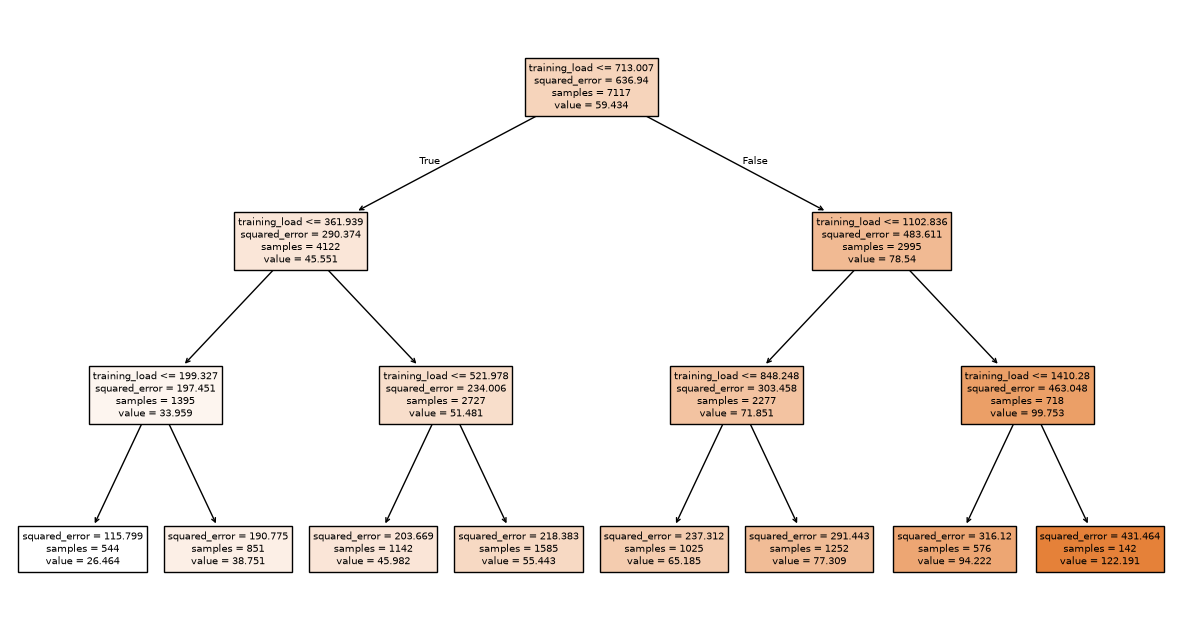

In [25]:
model_dt = DecisionTreeRegressor(max_depth=3, random_state=42)
model_dt.fit(X_train, y_train)
print_score(model_dt)

plt.figure(figsize=(15, 8))
plot_tree(model_dt, filled=True, feature_names=X_train.columns)
plt.show()

C:\Users\Nael\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
C:\Users\Nael\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
C:\Users\Nael\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
C:\Users\Nael\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
C:\Users\Nael\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
C:\Users\Nael\anaconda3\Lib\site-packages\sklearn\utils\validation.py:

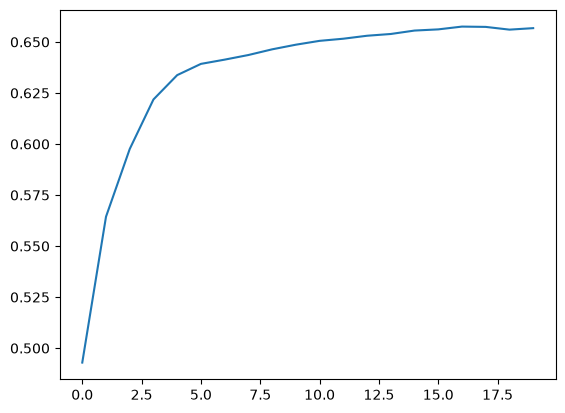

In [26]:
model = RandomForestRegressor(n_estimators=20, max_depth=10, random_state=42)
model.fit(X_train, y_train)

preds = np.stack([tree.predict(X_valid) for tree in model.estimators_])

plt.plot([metrics.r2_score(y_valid, np.mean(preds[:k], axis=0)) for k in range(1, 21)])
plt.show()

In [27]:
preds[:, 0], np.mean(preds[:, 0]), y_valid[0]

(array([47.61525538, 65.72309902, 67.97776702, 80.21330106, 42.8791783 ,
        52.05214768, 52.98665196, 34.95757911, 64.37972919, 45.23741293,
        54.86499774, 78.48753775, 61.25811467, 60.3624197 , 44.21200896,
        59.52726389, 70.03871176, 63.19004032, 55.14601183, 61.45464149]),
 np.float64(58.12819348758255),
 np.float64(111.80695832404942))

In [28]:
model = RandomForestRegressor(n_estimators=40, max_depth=10, oob_score=True, random_state=42)
model.fit(X_train, y_train)
print_score(model)

R2 train : 0.8556729758460992
R2 valid : 0.6630354124200877
R2 oob   : 0.6734326379944823


## Réglage des paramètres de la forêt

On teste toutes les combinaisons de ces paramètres du cours 3, et on garde celle qui a le meilleur R² en validation :

- `max_depth` : nombre maximum de questions à la suite dans un arbre (10 ou 20).
- `min_samples_split` : une case doit contenir au moins ce nombre de séances pour qu'on ait le droit de la couper en deux (2, 10 ou 20).
- `min_samples_leaf` : chaque feuille, au bout de l'arbre, doit garder au moins ce nombre de séances (1, 5 ou 10).
- `max_features` : part des variables tirées au hasard à chaque question (100 %, 50 % ou 33 %).
- `max_samples` : part des séances tirées au hasard pour construire chaque arbre (75 % ou 100 %).

Si `min_samples_split` est plus petit que 2 × `min_samples_leaf`, il ne change rien : couper une case en deux feuilles d'au moins `min_samples_leaf` séances demande déjà 2 × `min_samples_leaf` séances. C'est pour ça que certaines lignes du tableau ont exactement le même score.

On choisit ensuite le nombre d'arbres (`n_estimators`).

In [29]:
resultats = []
for depth in [10, 20]:
    for split in [2, 10, 20]:
        for leaf in [1, 5, 10]:
            for features_part in [1.0, 0.5, 0.33]:
                for samples in [0.75, 1.0]:
                    m = RandomForestRegressor(n_estimators=100, max_depth=depth,
                                              min_samples_split=split, min_samples_leaf=leaf,
                                              max_features=features_part, max_samples=samples,
                                              oob_score=True, random_state=42, n_jobs=-1)
                    m.fit(X_train, y_train)
                    resultats.append({
                        'max_depth': depth,
                        'min_samples_split': split,
                        'min_samples_leaf': leaf,
                        'max_features': features_part,
                        'max_samples': samples,
                        'R2 train': m.score(X_train, y_train),
                        'R2 valid': m.score(X_valid, y_valid),
                        'R2 oob': m.oob_score_,
                    })

resultats = pd.DataFrame(resultats).sort_values('R2 valid', ascending=False)
print(len(resultats), 'reglages testes')
resultats.head(15).round(3)

108 reglages testes


,max_depth,min_samples_split,min_samples_leaf,max_features,max_samples,R2 train,R2 valid,R2 oob
2,10,2,1,0.5,0.75,0.837,0.668,0.685
42,10,20,5,1.0,0.75,0.804,0.668,0.686
36,10,20,1,1.0,0.75,0.808,0.668,0.684
25,10,10,5,1.0,1.00,0.839,0.667,0.686
7,10,2,5,1.0,1.00,0.839,0.667,0.686
0,10,2,1,1.0,0.75,0.845,0.667,0.684
96,20,20,5,1.0,0.75,0.830,0.667,0.686
43,10,20,5,1.0,1.00,0.817,0.667,0.686
1,10,2,1,1.0,1.00,0.858,0.667,0.682
19,10,10,1,1.0,1.00,0.843,0.667,0.683


In [30]:
# on garde le reglage qui a le meilleur R2 en validation
meilleur = resultats.iloc[0]
print(meilleur)

# puis on choisit le nombre d'arbres avec ce reglage
# ajouter des arbres ne fait pas apprendre par coeur : on garde le dernier modele (400 arbres)
for n in [100, 200, 400]:
    model = RandomForestRegressor(n_estimators=n,
                                  max_depth=int(meilleur['max_depth']),
                                  min_samples_split=int(meilleur['min_samples_split']),
                                  min_samples_leaf=int(meilleur['min_samples_leaf']),
                                  max_features=meilleur['max_features'],
                                  max_samples=meilleur['max_samples'],
                                  oob_score=True, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    print('\nn_estimators =', n)
    print_score(model)

max_depth            10.000000
min_samples_split     2.000000
min_samples_leaf      1.000000
max_features          0.500000
max_samples           0.750000
R2 train              0.836746
R2 valid              0.667720
R2 oob                0.685019
Name: 2, dtype: float64



n_estimators = 100
R2 train : 0.8367455898767239
R2 valid : 0.6677196270329244
R2 oob   : 0.6850187627823956



n_estimators = 200
R2 train : 0.8377358589829847


R2 valid : 0.6671530654000521
R2 oob   : 0.6867899259868493



n_estimators = 400


R2 train : 0.8381867859186998


R2 valid : 0.6672714194552412
R2 oob   : 0.6880795254787468


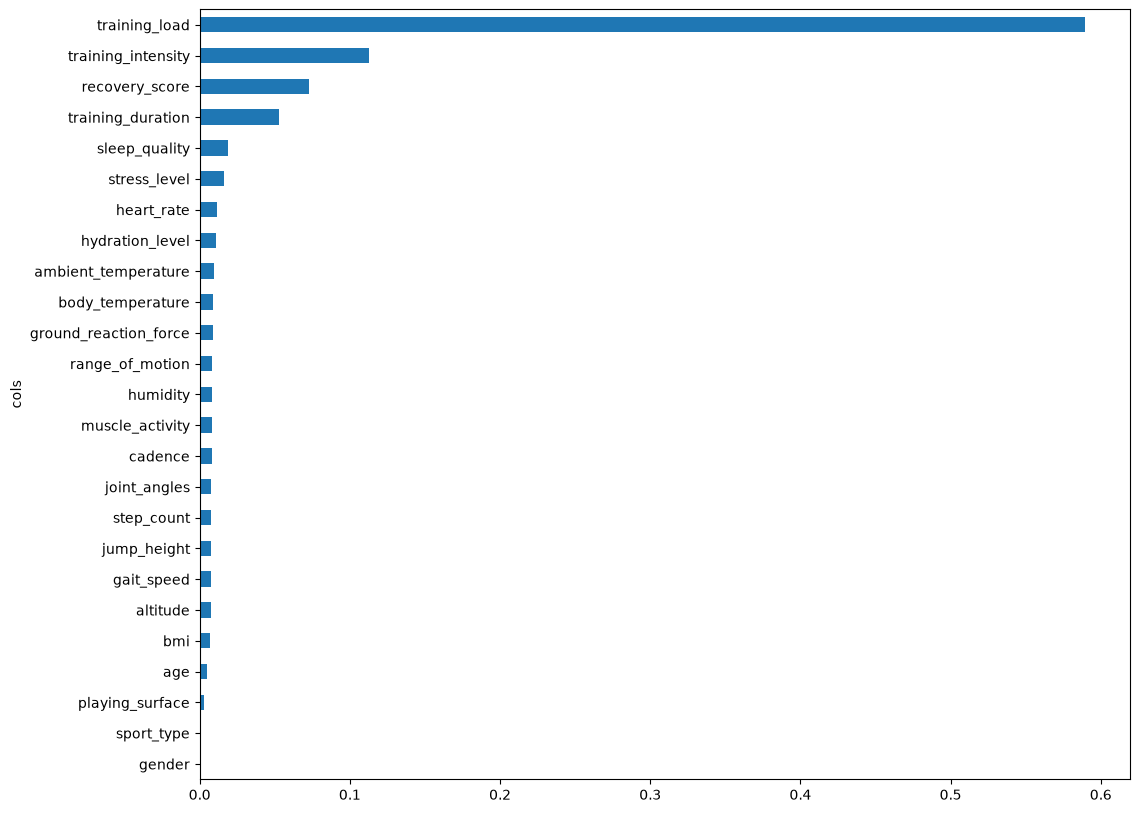

In [31]:
feat_importance = pd.DataFrame({
    'cols': X_train.columns,
    'imp': model.feature_importances_,
}).sort_values('imp', ascending=False)

feat_importance.plot('cols', 'imp', 'barh', figsize=(12, 10), legend=False).invert_yaxis()
plt.show()